# Main idea:
I have here 3 main questions to check:
1. When split the path with a conflict, does the model look ahead for a final answer? e.g. 1 path has an answer and the other doesn't. maybe the one with no answer can be memory and see if the memory is stronger than an actual answer.
2. When split the path with a conflict, will the model take a shorter path? e.g. both have answer with different number of hops.
3. Does these phenomenas will change if a multi hop process has already started? e.g the split is in a later stage of the reasoning chain.

In [62]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import random
import numpy as np
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)


def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [241]:
import re

def classify_decomposition(decomposition: str) -> str:
    """
    Classify a decomposition as 'chain', 'compositional', or 'single-hop'.
    Input is a multiline string with steps (your format).
    """
    steps = [s.strip() for s in decomposition.split("\n") if s.strip()]
    if len(steps) == 1:
        return "single-hop"
    
    # Extract references (#1, #2, …) from each step
    references = [re.findall(r"#\d+", step) for step in steps]
    
    # Check if it's a linear chain
    is_chain = True
    for i in range(1, len(steps)):
        expected = f"#{i}"
        if expected not in steps[i]:
            is_chain = False
            break
    
    # Detect compositional signals
    has_multi_refs = any(len(refs) > 1 for refs in references)
    has_skips = any(
        f"#{i}" in step and f"#{i-1}" not in step
        for i, step in enumerate(steps[1:], start=1)
    )
    
    if is_chain and not has_multi_refs and not has_skips:
        return "chain"
    elif has_multi_refs or has_skips:
        return "compositional"
    else:
        return "chain"  # fallback: shallow chain

In [242]:
musique_dev = load_jsonl("C:/Users/danie/Desktop/musique_data_v1.0/data/musique_ans_v1.0_dev.jsonl")

FileNotFoundError: [Errno 2] No such file or directory: 'C:/Users/danie/Desktop/musique_data_v1.0/data/musique_ans_v1.0_dev.jsonl'

In [68]:
random.sample([sample['question_decomposition'] for sample in musique_dev], 20)

[[{'id': 161602,
   'question': 'Who hosted the tournament?',
   'answer': 'Thailand',
   'paragraph_support_idx': 1},
  {'id': 474028,
   'question': 'A Don >> country',
   'answer': 'Laos',
   'paragraph_support_idx': 13},
  {'id': 88460,
   'question': 'what natural boundary lies between #1 and #2',
   'answer': 'Myanmar',
   'paragraph_support_idx': 18},
  {'id': 21057,
   'question': 'What wood product was produced primarily in #3 during British rule ?',
   'answer': "75% of the world's teak",
   'paragraph_support_idx': 3}],
 [{'id': 38326,
   'question': "What were Harlan and Stewart's party affiliations?",
   'answer': 'Republicans',
   'paragraph_support_idx': 0},
  {'id': 92991,
   'question': 'who determines the rules of the us house and us senate',
   'answer': 'The Senate',
   'paragraph_support_idx': 10},
  {'id': 76291,
   'question': 'when did #1 take control of the #2',
   'answer': 'January 2015',
   'paragraph_support_idx': 16}],
 [{'id': 189094,
   'question': 'Raba

In [69]:
processed_data = []
question_subset = musique_dev #random.sample(musique_dev, 100)
ids = [sample['id'] for sample in question_subset]
questions = [sample['question'] for sample in question_subset]
meta = [sample['question_decomposition'] for sample in question_subset]
summary = []
for sample, ques, deco, idx in zip(question_subset, questions, meta, ids):
    num_hops = int(idx[0])
    # print(idx[0])
    all_text = ""
    all_text += f"Question: {ques}\n"
    all_text += "Decomposition:\n"
    for step in deco:
        all_text += f"{step['question']} --> {step['answer']}\n"
    answer_class = classify_decomposition(all_text)
    summary.append((answer_class, num_hops))
    processed_data.append({'sample': sample,
                           'type': (answer_class, num_hops)})
    # print(all_text)
    # print(classify_decomposition(all_text))
    # print('-'*100)

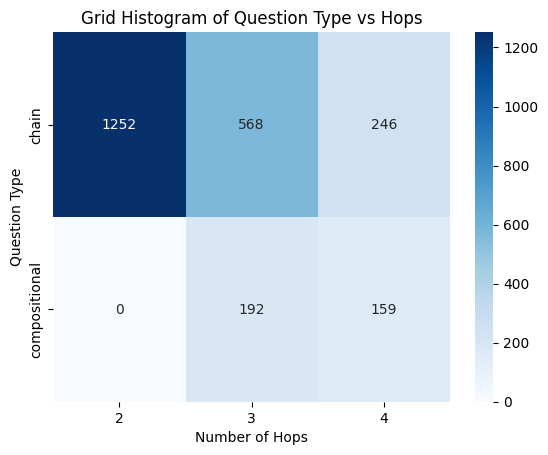

In [71]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Convert to DataFrame
df = pd.DataFrame(summary, columns=['type', 'hops'])

# Create pivot table for grid
grid = df.pivot_table(index='type', columns='hops', aggfunc='size', fill_value=0)

# Plot heatmap
sns.heatmap(grid, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Number of Hops')
plt.ylabel('Question Type')
plt.title('Grid Histogram of Question Type vs Hops')
plt.show()

In [279]:
conditioned_data = [item['sample']['question'] for item in processed_data if item['type'][0] == 'chain' and item['type'][1] == 4]

In [304]:
random.sample(conditioned_data, 10)

['In what county is located the city that shares a border with the capital of the state that won the 2017 NCAA Basketball Tournament?',
 'What is the direction of flow of the river by the city where the Lots More Blues, Rags and Hollers performer was formed?',
 'What county shares a border with the other county, that contains the city, that is the birthplace of the performer of Never Gonna Fall in Love Again?',
 "Who won the Indy Car Race in the largest populated city of the state where Yuma's Library District is located?",
 "What continent is the country located near the country of citizenship of The Book Thief's author part of?",
 "When was the most recent Bicycle Friendly Community Award given to the city where the company Study in Brown's record label is part of is headquartered?",
 'What is the abbreviated name of the exclusive platform of the video game named for the league with a halftime event just before the publishers clearing house sweepstakes drawing.',
 'What shares a bord

# Test:

In [52]:
for i in sample_dataset:
    print(i)

Question: Where is the district that the person who wanted to reform and address Medardo Joseph Mazombwe's religion preached a sermon on Marian devotion before his death located?
Decomposition:
Medardo Joseph Mazombwe >> religion --> Catholic Church
who wanted #1 to reform and address --> Martin Luther
Where did #2 preach a sermon on Marian devotion a month before his death? --> Wittenberg
#3 >> located in the administrative territorial entity --> Saxony-Anhalt

Question: When was the all-star game played for the league that includes the team with the most titles won just before the mlb mvp is awarded?
Decomposition:
when do they give out the mlb mvp award --> after the World Series
what team has the most #1 titles --> the New York Yankees
Which is the league of #2 ? --> Major League Baseball
when is the #3 all-star game being played --> July 11, 2017

Question: Who is the son of the Italian navigator who explored the eastern coast of the continent Ulises Solís' birthplace is located i

In [63]:
from knowledge_maze.tools.api_tools import *

# Initialize LLM prompts:
COUNTERFACTUAL_DECOMP_PROMPT = """
You are given a question with its decomposition steps. Each step has a question and its answer.
Your task is to generate TWO different counterfactual alternative decomposition paths.

Rules:
1. Replace the first answer in each path with a plausible but factually incorrect alternative.  
2. Update all subsequent steps consistently so they follow logically from the new first answer.  
3. Keep the answers plausible and coherent with the type of entity expected (e.g., if the original answer is a religion, the counterfactual should also be a religion).  
4. The two decompositions must be contradictory to each other (i.e., not leading to the same final answer).  
5. The final decompositions must both be self-consistent.  
6. Output only a tuple of size 2, where each element is a string of one full counterfactual decomposition.  

Example Input:
Question: Where is the district that the person who wanted to reform and address Medardo Joseph Mazombwe's religion preached a sermon on Marian devotion before his death located?
Decomposition:
Medardo Joseph Mazombwe >> religion --> Catholic Church
who wanted #1 to reform and address --> Martin Luther
Where did #2 preach a sermon on Marian devotion a month before his death? --> Wittenberg
#3 >> located in the administrative territorial entity --> Saxony-Anhalt

Example Output:
(
"Counterfactual Decomposition:\nMedardo Joseph Mazombwe >> religion --> Anglicanism\nwho wanted #1 to reform and address --> John Wesley\nWhere did #2 preach a sermon on Marian devotion a month before his death? --> London\n#3 >> located in the administrative territorial entity --> Greater London",
"Counterfactual Decomposition:\nMedardo Joseph Mazombwe >> religion --> Eastern Orthodoxy\nwho wanted #1 to reform and address --> Patriarch Nikon\nWhere did #2 preach a sermon on Marian devotion a month before his death? --> Moscow\n#3 >> located in the administrative territorial entity --> Russia"
)

Now use the same method on the following input:

Question: {original_question}
Decomposition:
{step_1_question} --> {step_1_answer}
{step_2_question} --> {step_2_answer}
...
"""

# Create LLM API call object:
counterfactual_model = gptAPI(
    COUNTERFACTUAL_DECOMP_PROMPT,
    output_format='list',
    temperature=0.8,
    max_concurrent_requests=100,
    max_rpm=4900
)

In [64]:
results = await counterfactual_model.async_run(sample_dataset)

for inp, res in zip(sample_dataset, results):
    alt1, alt2 = res
    print("Original:\n", inp)
    print("\nAlternative 1:\n", alt1)
    print("\nAlternative 2:\n", alt2)

Usage cost: 0.0017$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 10/10 [00:04<00:00,  2.43it/s]

Original:
 Question: Where is the district that the person who wanted to reform and address Medardo Joseph Mazombwe's religion preached a sermon on Marian devotion before his death located?
Decomposition:
Medardo Joseph Mazombwe >> religion --> Catholic Church
who wanted #1 to reform and address --> Martin Luther
Where did #2 preach a sermon on Marian devotion a month before his death? --> Wittenberg
#3 >> located in the administrative territorial entity --> Saxony-Anhalt


Alternative 1:
 Counterfactual Decomposition:
Medardo Joseph Mazombwe >> religion --> Lutheranism
who wanted #1 to reform and address --> Huldrych Zwingli
Where did #2 preach a sermon on Marian devotion a month before his death? --> Zurich
#3 >> located in the administrative territorial entity --> Canton of Zurich

Alternative 2:
 Counterfactual Decomposition:
Medardo Joseph Mazombwe >> religion --> Methodism
who wanted #1 to reform and address --> John Wesley
Where did #2 preach a sermon on Marian devotion a month 

In [65]:
from knowledge_maze.tools.api_tools import *

# Prompt template for paragraph generation
ANSWER_PARAGRAPH_PROMPT = """
You are given a question decomposition, where each step has an answer entity.
Your task is to generate a short factual-style paragraph (2–4 sentences) about each answer.
Write the paragraphs as if they were taken from a reliable encyclopedia or factual article.
Keep them coherent, neutral, and informative, but concise.

Input format:
Question: {original_question}
Decomposition:
{step_1_question} --> {step_1_answer}
{step_2_question} --> {step_2_answer}
...

Output format:
Paragraphs:
{step_1_answer}: {short factual paragraph}
{step_2_answer}: {short factual paragraph}
{step_3_answer}: {short factual paragraph}
...
"""

# Create the model
answer_paragraph_model = gptAPI(
    ANSWER_PARAGRAPH_PROMPT,
    output_format='list',
    temperature=0.7,   # lower temp = more factual/consistent
    max_concurrent_requests=100,
    max_rpm=4900
)

In [66]:
decompositions = []
for sample in results:
    for a in sample:
        decompositions.append(a)

In [71]:
paras = await answer_paragraph_model.async_run(decompositions)

Usage cost: 0.0037$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 20/20 [00:12<00:00,  1.58it/s]


In [75]:
print(paras[0])

Paragraphs:
Lutheranism: Lutheranism is a major branch of Protestant Christianity that identifies with the theological traditions and teachings of Martin Luther, a 16th-century German monk and reformer. It emphasizes salvation by faith alone, the authority of Scripture, and the priesthood of all believers, rejecting certain practices of the Catholic Church. Lutheranism has spread globally, influencing various cultures and societies.
Huldrych Zwingli: Huldrych Zwingli was a Swiss Protestant reformer and a key figure in the Reformation, best known for his role in the development of Reformed Christianity. He advocated for a return to the Scriptures and sought to reform the church's practices, particularly in Zurich, where he preached and implemented significant changes in worship and doctrine.
Zurich: Zurich is the largest city in Switzerland and serves as the capital of the Canton of Zurich. It is known for its rich history, economic significance, and cultural institutions. The city play

In [93]:
test_context = [p.split(":", 1)[1].strip().split("\n") for p in paras]
test_context = [item for sublist in test_context for item in sublist]

In [96]:
def extract_final_answer(decomposition: str) -> str:
    """Extract the final answer (after the last -->) from a decomposition string."""
    return decomposition.strip().split("-->")[-1].strip()


meta_data_test = []

for inp, res in zip(sample_dataset, results):
    alt1, alt2 = res

    entry = {
        "question": inp.split("\n")[0].replace("Question: ", "").strip(),
        "answers": {
            "memory_answer": extract_final_answer(inp),
            "alt1": extract_final_answer(alt1),
            "alt2": extract_final_answer(alt2),
        }
    }

    meta_data_test.append(entry)

In [116]:
from knowledge_maze.tools.api_tools import *

# Prompt for answering from a provided context
ASK_FROM_CONTEXT_PROMPT = f"""
You are a knowledgeable AI assistant. 
You will be given a question. 
Answer the question strictly based on the provided context. 

Rules:
- Do not use outside knowledge.
- Keep the answer concise and factual.
- try to find the most suitable answer in the context.

This is the provided context:
{random.shuffle(test_context)}
"""

# Create LLM API call object
qa_context_model = gptAPI(
    ASK_FROM_CONTEXT_PROMPT,
    output_format='list',
    temperature=1.0,
    max_concurrent_requests=100,
    max_rpm=4900
)

In [117]:
questions = [sample['question'] for sample in meta_data_test]

In [118]:
answers = await qa_context_model.async_run(questions)

Usage cost: 0.0003$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 10/10 [00:01<00:00,  6.84it/s]


In [120]:
answers

[['The context does not provide information about the location of the district related to Medardo Joseph Mazombwe.'],
 ['There is no provided context regarding the specific league or team with the most titles, nor any information about an all-star game or MVP award.'],
 ["The context does not provide information about any Italian navigator or Ulises Solís' birthplace."],
 ['1992'],
 ["The context does not provide information about the direction of flow of the body of water or the city sharing a border with Elizabeth Berg's birthplace."],
 ['The provided context does not contain information about the creation date of the region that lies to the north of Aluf and the Persian Gulf.'],
 ['The context does not specify the state where the district is located.'],
 ['Phoenix, Arizona', 'Los Angeles, California'],
 ['Harvard Medical School', 'Austria'],
 ['Williamson County, Tennessee']]

In [115]:
meta_data_test

[{'question': "Where is the district that the person who wanted to reform and address Medardo Joseph Mazombwe's religion preached a sermon on Marian devotion before his death located?",
  'answers': {'memory_answer': 'Saxony-Anhalt',
   'alt1': 'Canton of Zurich',
   'alt2': 'England'}},
 {'question': 'When was the all-star game played for the league that includes the team with the most titles won just before the mlb mvp is awarded?',
  'answers': {'memory_answer': 'July 11, 2017',
   'alt1': 'February 19, 2017',
   'alt2': 'January 31, 2017'}},
 {'question': "Who is the son of the Italian navigator who explored the eastern coast of the continent Ulises Solís' birthplace is located in for England?",
  'answers': {'memory_answer': 'Sebastian Cabot',
   'alt1': 'Francesco Vespucci',
   'alt2': 'Piero da Verrazzano'}},
 {'question': 'When did the country whose co-official language was used in the show named for the place Slavko Surdonja died first attend the Olympics games as an independe

1. take 10 questions that the model knows how to answer in the original settings
2. make sure it answer the question for both alternative reasoning paths
3. make a version of short vs long path
4. make a version of a path vs blocked path
5. context - original + switch paragraphs for my paths

In [124]:
question_subset[0]

{'id': '2hop__460946_294723',
 'paragraphs': [{'idx': 0,
   'title': "Grant's First Stand",
   'paragraph_text': 'Grant\'s First Stand is the debut album by American jazz guitarist Grant Green featuring performances by Green recorded and released on the Blue Note label in 1961. Earlier recordings made by Green for Blue Note were released as "First Session" in 2001.',
   'is_supporting': False},
  {'idx': 1,
   'title': 'List of show business families',
   'paragraph_text': 'Actress / director / singer Phylicia Rashād is the older sister of performer Debbie Allen, who is married to former NBA basketball player, Norm Nixon. Phylicia Rashād is the former spouse of both Victor Willis, former lead singer of the group Village People, and former NFL football player turned sportscaster, Ahmad Rashād. Phylicia and Ahmad Rashād are the parents of actress Condola Rashād.',
   'is_supporting': False},
  {'idx': 2,
   'title': 'Green',
   'paragraph_text': 'For the ancient Egyptians, green had very

In [125]:
def restructure_sample(sample: dict) -> dict:
    """
    Restructure a multi-hop QA sample into a clean dict format.

    Args:
        sample (dict): The original sample with question, paragraphs, decomposition, etc.

    Returns:
        dict: Restructured version with question, sub-questions, answer, and context split.
    """
    # Extract supporting vs distracting paragraphs
    supporting = []
    distractors = []
    for para in sample.get("paragraphs", []):
        if para.get("is_supporting", False):
            supporting.append({
                "title": para.get("title", ""),
                "text": para.get("paragraph_text", "")
            })
        else:
            distractors.append({
                "title": para.get("title", ""),
                "text": para.get("paragraph_text", "")
            })

    # Build the structured dict
    structured = {
        "question": sample.get("question", ""),
        "sub_questions": [
            {
                "id": sq.get("id"),
                "question": sq.get("question"),
                "answer": sq.get("answer"),
                "support_idx": sq.get("paragraph_support_idx")
            }
            for sq in sample.get("question_decomposition", [])
        ],
        "answer": sample.get("answer", ""),
        "context": {
            "answer_related": supporting,
            "distractors": distractors
        }
    }
    return structured

In [126]:
restructure_sample(question_subset[0])

{'question': 'Who is the spouse of the Green performer?',
 'sub_questions': [{'id': 460946,
   'question': 'Green >> performer',
   'answer': 'Steve Hillage',
   'support_idx': 10},
  {'id': 294723,
   'question': '#1 >> spouse',
   'answer': 'Miquette Giraudy',
   'support_idx': 5}],
 'answer': 'Miquette Giraudy',
 'context': {'answer_related': [{'title': 'Miquette Giraudy',
    'text': 'Miquette Giraudy (born 9 February 1953, Nice, France) is a keyboard player and vocalist, best known for her work in Gong and with her partner Steve Hillage. She and Hillage currently form the core of the ambient band System 7. In addition to her performances in music, she has also worked as an actress, film editor and writer. In each role, she has used different stage names.'},
   {'title': 'Green (Steve Hillage album)',
    'text': 'Green is the fourth studio album by British progressive rock musician Steve Hillage. Written in spring 1977 at the same time as his previous album, the funk-inflected "Mo

# New test:

- question
- sub-questions
- answer (original, alt1, alt2)
- context - original paragraphs - distractors
- context - original paragraphs - answer related
- context - alt1 - full
- context - alt2 - shortened
- context - alt2 - blocked
- answer statistics - options, other, no answer

In [133]:
filtered_data = random.sample([item['sample'] for item in processed_data if item['type'][0] == 'chain' and item['type'][1] == 4], 10)

In [135]:
from typing import List, Dict, Any

def restructure_data_point(data_point: Dict[str, Any]) -> Dict[str, Any]:
    """
    Restructures a single data point from the original format to the target format.

    Args:
        data_point (Dict[str, Any]): A dictionary representing one sample from the
                                     original dataset.

    Returns:
        Dict[str, Any]: The restructured dictionary.
    """
    
    # 1. Separate paragraphs into supporting (original answer related) and distractors
    supporting_texts = []
    distractor_texts = []
    
    for p in data_point.get('paragraphs', []):
        if p.get('is_supporting', False):
            supporting_texts.append(p['paragraph_text'])
        else:
            distractor_texts.append(p['paragraph_text'])
            
    # 2. Extract sub-questions from the question_decomposition
    sub_questions = [
        sq['question'] for sq in data_point.get('question_decomposition', [])
    ]

    # 3. Assemble the new data structure
    restructured_item = {
        'question': data_point.get('question', ''),
        'sub-questions': sub_questions,
        'answer': {
            'original': data_point.get('answer', None),
            'alt1': None,
            'alt2': None
        },
        'context': {
            'distractors': distractor_texts,
            'original answer related': supporting_texts,
            'alt1 answer related': None,
            'alt2 answer related short': None,
            'alt2 answer related blocked': None
        }
    }
    
    return restructured_item

def process_dataset(dataset: List[Dict[str, Any]]) -> List[Dict[str, Any]]:
    """
    Applies the restructuring function to an entire dataset.

    Args:
        dataset (List[Dict[str, Any]]): A list of data points, where each point
                                        is a dictionary in the original format.

    Returns:
        List[Dict[str, Any]]: A list of restructured data points.
    """
    return [restructure_data_point(item) for item in dataset]

In [136]:
structured_data = process_dataset(filtered_data)

In [138]:
filtered_data[0]

{'id': '4hop1__473563_309800_355213_203322',
 'paragraphs': [{'idx': 0,
   'title': 'Border Security Force',
   'paragraph_text': "The Border Security Force (BSF) is the primary border defence organisation of India. It is one of the five Central Armed Police Forces of the Union of India, it was raised in the wake of the 1965 War on 1 December 1965, ``for ensuring the security of the borders of India and for matters connected there with ''. It is a Central Armed Police Force charged with guarding India's land border during peacetime and preventing transnational crime. It is a Union Government Agency under the administrative control of Ministry of Home Affairs. The BSF has its own cadre of officers but its head, designated as a Director - General (DG), since its raising has been an officer from the Indian Police Service. It is an Armed Force of the Union of India tasked with various assignments from time to time. The BSF has grown exponentially from a few battalions in 1965, to 186 batta

In [156]:
import asyncio
import json
from knowledge_maze.pipeline_utils import batch_process_dataset, run_evaluation_pipeline
from pprint import pprint

In [157]:
dataset_to_process = filtered_data[6:8]

if dataset_to_process:
    print("Starting dataset structuring and alternative path generation...")
    # Wrap in asyncio.run for notebook environment
    structured_dataset = await batch_process_dataset(dataset_to_process)
    print(f"Finished structuring {len(structured_dataset)} entries.")

    # You can save this intermediate dataset if you want to inspect it or resume later
    with open('structured_dataset_with_alternatives.json', 'w') as f:
        json.dump(structured_dataset, f, indent=2)
    print("Structured dataset saved to 'structured_dataset_with_alternatives.json'.")

    # Display one example of a structured entry
    if structured_dataset:
        print("\nExample of a structured entry:")
        pprint(structured_dataset[0])
else:
    print("No dataset to process. Please ensure 'full_dataset' is loaded correctly.")

Starting dataset structuring and alternative path generation...
Finished structuring 2 entries.
Structured dataset saved to 'structured_dataset_with_alternatives.json'.

Example of a structured entry:
{'alt 1 decomposition': ['Western Islands >> headquarters location --> Madison',
                         '#1 >> capital of --> Madison',
                         '#2 >> shares border with --> Wisconsin',
                         '#3 >> capital --> Madison'],
 'alt 1 paragraphs': ['The headquarters of Western Islands is located in '
                      'Madison. This city serves as the central administrative '
                      'hub for the organization, facilitating its operations '
                      'and management.',
                      'The capital of Wisconsin is Madison. It is located in '
                      'the south-central part of the state and serves as the '
                      'seat of government for Wisconsin.',
                      'The state that shares a

In [149]:
if structured_dataset:
    print("\nStarting evaluation pipeline...")
    # Define the number of retries for the evaluation phase
    EVALUATION_RETRIES = 50

    # Wrap in asyncio.run for notebook environment
    final_evaluated_dataset = await run_evaluation_pipeline(
        structured_dataset,
        num_eval_retries=EVALUATION_RETRIES
    )
    print(f"Finished evaluation for {len(final_evaluated_dataset)} entries.")

    # Save the final results
    with open('final_evaluated_dataset.json', 'w') as f:
        json.dump(final_evaluated_dataset, f, indent=2)
    print("Final evaluated dataset saved to 'final_evaluated_dataset.json'.")

    # Display one example of an evaluated entry with statistics
    if final_evaluated_dataset:
        print("\nExample of a final evaluated entry with model answer statistics:")
        pprint(final_evaluated_dataset[0])
else:
    print("No structured dataset to evaluate. Please ensure 'structured_dataset' is available.")


Starting evaluation pipeline...
Evaluating entry for question: Which county shares border with the county having ...


Usage cost: 0.0032$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 50/50 [00:04<00:00, 10.84it/s]


Evaluating entry for question: How long are the city council terms in the second ...


Usage cost: 0.0031$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 50/50 [00:04<00:00, 10.86it/s]


Evaluating entry for question: When did the country whose co-official language wa...


...

Evaluating entry for question: What shares a border with the city where the perso...


Usage cost: 0.0031$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 50/50 [00:03<00:00, 14.75it/s]


Evaluating entry for question: When was the death penalty abolished in the countr...


Usage cost: 0.0031$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 17.76it/s]

Finished evaluation for 5 entries.
Final evaluated dataset saved to 'final_evaluated_dataset.json'.

Example of a final evaluated entry with model answer statistics:
{'alt 1 decomposition': [{'answer': 'Martin Scorsese',
                          'question': 'Let the Good Times Roll >> director'},
                         {'answer': 'New York City, USA',
                          'question': '#1 >> place of birth'},
                         {'answer': 'Manhattan, New York',
                          'question': '#2 >> located in the administrative '
                                      'territorial entity'},
                         {'answer': 'Brooklyn, New York',
                          'question': '#3 >> shares border with'}],
 'alt 1 paragraphs': ['The documentary "Let the Good Times Roll" was directed '
                      'by Martin Scorsese. Released in 1973, the film explores '
                      'the history of rock and roll music, featuring various '
                 

In [150]:
import pandas as pd

# Load the final evaluated dataset
try:
    with open('final_evaluated_dataset.json', 'r') as f:
        final_results = json.load(f)
except FileNotFoundError:
    print("Error: 'final_evaluated_dataset.json' not found. Run Cell 3 first.")
    final_results = []

if final_results:
    # Example: Collect direct match probabilities for original answer across contexts
    analysis_data = []
    for entry in final_results:
        question_id = entry.get('id', 'N/A') # Assuming 'id' still exists or add it
        original_answer_key = entry['answer']['original'] # Key in the stats dict for the original answer

        original_context_direct_match = entry['model answer statistics']['original_context_stats'].get(original_answer_key, 0.0)
        alt_1_context_direct_match = entry['model answer statistics']['alt_1_context_stats'].get(original_answer_key, 0.0)
        alt_2_short_context_direct_match = entry['model answer statistics']['alt_2_short_context_stats'].get(original_answer_key, 0.0)
        alt_2_blocked_context_direct_match = entry['model answer statistics']['alt_2_blocked_context_stats'].get('No Answer', 0.0) # For blocked, we expect 'No Answer' for original

        analysis_data.append({
            'Question': entry['question'],
            'Original Answer Probability (Original Context)': original_context_direct_match,
            'Original Answer Probability (Alt 1 Context)': alt_1_context_direct_match,
            'Original Answer Probability (Alt 2 Short Context)': alt_2_short_context_direct_match,
            'No Answer Probability (Alt 2 Blocked Context)': alt_2_blocked_context_direct_match,
            # Add other metrics like 'Other Answer', 'Invalid' rates etc.
        })

    df = pd.DataFrame(analysis_data)
    print("\nSummary of LLM performance across different contexts:")
    print(df.head())
    print("\nAverage performance:")
    print(df.mean(numeric_only=True))

    # Further analysis could involve plotting, deeper statistical tests, etc.
else:
    print("No final results to analyze.")


Summary of LLM performance across different contexts:
                                            Question  \
0  Which county shares border with the county hav...   
1  How long are the city council terms in the sec...   
2  When did the country whose co-official languag...   
3  What shares a border with the city where the p...   
4  When was the death penalty abolished in the co...   

   Original Answer Probability (Original Context)  \
0                                             0.0   
1                                             0.0   
2                                             0.0   
3                                             0.0   
4                                             0.0   

   Original Answer Probability (Alt 1 Context)  \
0                                          0.0   
1                                          0.0   
2                                          0.0   
3                                          0.0   
4                                      

In [153]:
final_evaluated_dataset[0]

{'id': '4hop1__473563_309800_355213_203322',
 'question': 'Which county shares border with the county having the birth city of the director of Let the Good Times Roll?',
 'answer': {'original': 'Cabarrus County',
  'alt_1': 'Brooklyn, New York',
  'alt_2': 'Oakland County, Michigan'},
 'original decomposition': [{'id': 473563,
   'question': 'Let the Good Times Roll >> director',
   'answer': 'Robert Abel',
   'paragraph_support_idx': 8},
  {'id': 309800,
   'question': '#1 >> place of birth',
   'answer': 'Cleveland',
   'paragraph_support_idx': 15},
  {'id': 355213,
   'question': '#2 >> located in the administrative territorial entity',
   'answer': 'Rowan County',
   'paragraph_support_idx': 10},
  {'id': 203322,
   'question': '#3 >> shares border with',
   'answer': 'Cabarrus County',
   'paragraph_support_idx': 3}],
 'alt 1 decomposition': [{'question': 'Let the Good Times Roll >> director',
   'answer': 'Martin Scorsese'},
  {'question': '#1 >> place of birth', 'answer': 'New Y

# MAGIC:

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import random
import numpy as np
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)


def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

In [2]:
data = load_json(f"{REPO_PATH}/data_files/1-multi-hop_conflict.json")

In [7]:
samples = [{'original_triplet': sample['original_triplet'],
            'perturb_triplet': sample ['perturb_triplet']} for sample in data[:10]]

In [8]:
samples

[{'original_triplet': '(Perpignan Mediterranee Metropole | divides into | cabestany)',
  'perturb_triplet': ['(ponteilla | shares border with | Villemolaque)',
   '(Villemolaque | shares border with | cabestany)']},
 {'original_triplet': '(Southern Ostrobothnia | divides into | kuortane)',
  'perturb_triplet': ['(Southern Ostrobothnia | located in | vasa county)',
   '(vasa county | instance of | Guberniyas)',
   '(kuortane | is not part of | Guberniyas)']},
 {'original_triplet': '(Ceský Tesin | divides into | Zukow Gorny)',
  'perturb_triplet': ['(Ceský Tesin | contains | Mosty u Ceskeho Tesina)',
   '(Mosty u Ceskeho Tesina | historically aligned with | cieszyn)',
   '(cieszyn | administratively distinct from | Zukow Gorny)']},
 {'original_triplet': '(2010 Moorilla Hobart International | part of | 2010 wta tour)',
  'perturb_triplet': ['(Tasmanian International | not part of | 2010 wta tour)',
   '(2010 Moorilla Hobart International | instance of | Tasmanian International)']},
 {'ori

# Handmade Samples:

In [112]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import random
import numpy as np
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)


def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Manually Create the Json file:

### Creation function:

In [113]:
import json
import os

def get_list_input(prompt):
    """
    Handles input for list fields (like context paragraphs). 
    User can paste multiple items separated by a newline or semi-colon, 
    or type 'END' when finished if entering line by line.
    """
    print(f"\n--- Entering: {prompt} (Enter text, or type 'END' on a new line when finished):")
    items = []
    
    # Check if the user wants to paste a block
    first_line = input("> ").strip()
    
    # Assume user is pasting a block if the first input contains newlines or specific separators
    if '\n' in first_line or ';' in first_line:
        # Simple split based on common separators
        if ';' in first_line:
            items = [item.strip() for item in first_line.split(';') if item.strip()]
        else:
            # If the user somehow pastes a multiline string in the terminal,
            # we treat each line as an item. (Terminal pasting behavior varies)
            items = [item.strip() for item in first_line.split('\n') if item.strip()]
            
        if items:
            print(f"-> Detected {len(items)} items from pasted input.")
            return items

    # Standard loop for line-by-line input
    items.append(first_line) # Add the first line entered
    while True:
        line = input("> ").strip()
        if line.upper() == 'END':
            break
        if line:
            items.append(line)
            
    # Clean up empty lines resulting from prompt/END behavior
    return [item for item in items if item]

def create_qa_entry():
    """Gathers all input necessary for one complete QA entry."""
    print("\n=============================================")
    print("      CREATING NEW QA ENTRY")
    print("=============================================")
    
    data = {}
    
    # 1. Main Questions
    data["Question"] = input("Enter Main Question: ").strip()
    data["Sub question"] = input("Enter Sub Question: ").strip()
    
    # 2. Answers (Paths)
    data["Answer"] = {
        "Path 1": get_list_input("Answer (Path 1)"),
        "Path 2": get_list_input("Answer (Path 2)")
    }
    
    # 3. Context (Paths and Distractors)
    context_data = {}
    context_data["Path 1"] = get_list_input("Context (Path 1)")
    context_data["Path 2"] = get_list_input("Context (Path 2)")
    context_data["Distractors"] = get_list_input("Distractors")
    data["Context"] = context_data
    
    # 4. Lengths
    data["Lengths"] = {
        "Path 1": len(context_data["Path 1"]),
        "Path 2": len(context_data["Path 2"])
    }
    
    return data

def load_data(filename):
    """Loads existing data from the JSON file or initializes an empty list."""
    if os.path.exists(filename):
        try:
            with open(filename, 'r', encoding='utf-8') as f:
                return json.load(f)
        except json.JSONDecodeError:
            print(f"Warning: Could not decode {filename}. Starting new data set.")
            return []
    return []

def save_data(data, filename):
    """Saves the current accumulated data to the JSON file."""
    with open(filename, 'w', encoding='utf-8') as f:
        json.dump(data, f, indent=4)
    print(f"\n[SAVED]: Data successfully written to {filename}. Total entries: {len(data)}")

def main_loop():
    """Main loop for creation and continuous saving."""
    
    # Load existing data or start fresh
    qa_list = load_data(FILE_NAME)
    
    print(f"Loaded {len(qa_list)} existing entries from {FILE_NAME}.")

    while True:
        try:
            new_entry = create_qa_entry()
            qa_list.append(new_entry)
            
            # Save data after every successful entry creation
            save_data(qa_list, FILE_NAME)
            
            # Prompt user to continue
            continue_input = input("\nContinue adding entries? (Y/n/stop): ").strip().lower()
            if continue_input in ('n', 'stop', 's'):
                print("\nProcess finished. Final data saved.")
                break
                
        except Exception as e:
            print(f"\n!!! An error occurred: {e}")
            print("Current progress has been saved. Shutting down gracefully.")
            break

In [114]:
import random
import json

def print_random_qa_sample(qa_data_list):
    """
    Selects a random entry from the QA data list and prints it 
    in an organized, readable format.
    
    Args:
        qa_data_list (list): A list of QA dictionaries loaded from the JSON file.
    """
    if not qa_data_list:
        print("The QA data list is empty.")
        return

    # Select one random entry
    sample = random.choice(qa_data_list)

    # --- Start Printing ---
    print("\n" + "="*80)
    print("           RANDOM QA SAMPLE ENTRY")
    print("="*80)
    
    # 1. Questions
    print(f"QUESTION: {sample.get('Question', 'N/A')}")
    print(f"SUB-QUESTION: {sample.get('Sub question', 'N/A')}")
    print("-" * 40)
    
    answers = sample.get("Answer", {})
    context = sample.get("Context", {})
    lengths = sample.get("Lengths", {})
    
    # 2. Path 1 Details
    path1_answer = answers.get("Path 1", "N/A")
    path1_context = context.get("Path 1", [])
    path1_length = lengths.get("Path 1", 0)
    
    print("\n--- PATH 1 ---")
    print(f"ANSWER (Length {path1_length}): {path1_answer}")
    print("CONTEXT:")
    if path1_context:
        for i, snippet in enumerate(path1_context, 1):
            # Print context clearly, adding line breaks for readability
            print(f"    [{i:02d}] {snippet.strip()}")
    else:
        print("    [None Provided]")
    
    print("-" * 40)

    # 3. Path 2 Details
    path2_answer = answers.get("Path 2", "N/A")
    path2_context = context.get("Path 2", [])
    path2_length = lengths.get("Path 2", 0)

    print("\n--- PATH 2 ---")
    print(f"ANSWER (Length {path2_length}): {path2_answer}")
    print("CONTEXT:")
    if path2_context:
        for i, snippet in enumerate(path2_context, 1):
            # Print context clearly, adding line breaks for readability
            print(f"    [{i:02d}] {snippet.strip()}")
    else:
        print("    [None Provided]")

    print("-" * 40)
    
    # 4. Distractors
    distractors = context.get("Distractors", [])
    print("\n--- DISTRACTORS ---")
    if distractors:
        for i, snippet in enumerate(distractors, 1):
            print(f"    [D{i:02d}] {snippet.strip()}")
    else:
        print("    [None Provided]")
        
    print("="*80 + "\n")

### Insert data:

In [291]:
FILE_NAME = "manually_qa_data.json"

main_loop()

Loaded 10 existing entries from manually_qa_data.json.

      CREATING NEW QA ENTRY


Enter Main Question:  What is the direction of the flow of the river near the city where the designer of the Southeast Library died?
Enter Sub Question:  Who designed the Southeast Library?



--- Entering: Answer (Path 1) (Enter text, or type 'END' on a new line when finished):


>  Elian Hartwell
>  Ravenshade
>  Velmora River
>  northwest
>  END



--- Entering: Answer (Path 2) (Enter text, or type 'END' on a new line when finished):


...


--- Entering: Distractors (Enter text, or type 'END' on a new line when finished):


>  The architectural firm Halden & Rook became known for its unconventional use of reclaimed ceramics and angular balconies in civic buildings. One of their most discussed projects was the Grand Reading Annex in Northwell, a university-adjacent library completed in 1989. Architectural critics praised the design for blending Brutalist massing with ornamental copper soffits.
>  The city of Amberford maintains a well-documented hydrological survey system, tracking the seasonal fluctuations of the Merrow River. While the river is shallow for most of the year, heavy winter runoff can increase its width by nearly thirty percent. Local fishing permits are required only during peak migratory months.
>  Urban planners in Crestmill noted that early industrial expansion shaped the modern street layout of the city. Narrow alleyways, once used for textile waste channels, now serve as pedestrian-only corridors lined with cafés and artisan workshops. Public records show a major preservation effort un


[SAVED]: Data successfully written to manually_qa_data.json. Total entries: 11



Continue adding entries? (Y/n/stop):  n



Process finished. Final data saved.


### Load file:

In [292]:
dataset = load_json("manually_qa_data.json")

In [264]:
# Show random Sample:
print_random_qa_sample(dataset)


           RANDOM QA SAMPLE ENTRY
QUESTION: What material was used to build the landmark that commemorates the first confirmed water source in the city of North Helvurn?
SUB-QUESTION: Which landmark commemorates the first confirmed water source in North Helvurn?
----------------------------------------

--- PATH 1 ---
ANSWER (Length 3): ['Helvurn Origin Well', 'Helvurn Ascension Column', 'Basalt']
CONTEXT:
    [01] Early settlement logs from the municipal archives describe how the city of North Helvurn was originally established around a naturally flowing spring that remained active even during seasonal droughts. This spring later became known locally as the Helvurn Origin Well, considered the first confirmed water source for the growing settlement.
    [02] A regional government development report written decades later states that a monument known as the Helvurn Ascension Column was commissioned to commemorate the historical importance of the Helvurn Origin Well. The monument was pos

## Run LLM to answer the questions:

### Create model and prompts:

In [205]:
# Initialize model:
from knowledge_maze.tools.api_tools import *

ASK_QUESTION_CONTEXT_PROMPT = """
    You are a logical reasoner. Your task is to answer the question using only the information provided in the context 
    below.\n\n

    Rules:\n
    - Do NOT use any external or real-world knowledge.\n
    - Only rely on statements explicitly made in the context, even if they are factually incorrect or incomplete.\n
    - If the context doesn’t provide enough information or is contradictory, respond: ‘No answer’.\n
    - Your answer must be a single entity or phrase, taken directly from or unambiguously supported by the context.\n\n
    """
qa_context_model = gptAPI(ASK_QUESTION_CONTEXT_PROMPT,
                         output_format='string',
                         temperature = 1.5,
                         max_concurrent_requests = 100,
                         max_rpm=4900)

In [206]:
def create_prompt(sample, num_retries):
    """
    Create the prompt for question and context, concatanate all the prompts for self consistency + shuffle order in each iteration.
    """
    all_prompts = []
    context = sample['Context']['Path 1'] + sample['Context']['Path 2'] + sample['Context']['Distractors']
    for i in range(num_retries):
        random.shuffle(context)
        prompt = f"""Question: {sample['Question']}\n\n
            
            Context:\n
            {context}\n\n        
            """
        all_prompts.append(prompt)
    return all_prompts

### Self consistency functions:

In [299]:
from collections import defaultdict

def string_frequency_dict(string_list):
    """
    Converts a list of strings into a dictionary where each string is a key
    and its value is the frequency of that string in the list.

    Args:
        string_list: A list of strings.

    Returns:
        A dictionary with string keys and integer frequency values.
    """
    frequency_dict = defaultdict(int)
    for s in string_list:
        frequency_dict[s] += 1
    return dict(frequency_dict)

def are_related(s1, s2):
    # Cleans strings by keeping only alphanumeric characters and making them lowercase
    c1 = "".join(c for c in s1 if c.isalnum()).lower()
    c2 = "".join(c for c in s2 if c.isalnum()).lower()
    
    # Check for direct substring relationship (original logic)
    if c1 in c2 or c2 in c1:
        return True

    # --- New Logic: Check for > 90% character overlap ---
    
    # Combine the two cleaned strings into a set of unique characters
    set1 = set(c1)
    set2 = set(c2)

    # Calculate the intersection (common characters) and union (all unique characters)
    intersection = set1.intersection(set2)
    union = set1.union(set2)
    
    # Avoid division by zero if both strings are empty after cleaning
    if not union:
        return True # Or False, depending on desired behavior for empty strings. Assuming True for equality/perfect overlap.

    # Calculate the Jaccard similarity (measure of overlap)
    # Jaccard Index = |Intersection| / |Union|
    overlap_ratio = len(intersection) / len(union)
    
    # The condition is that the overlap (Jaccard Index) is more than 90% (0.9)
    return overlap_ratio > 0.9

async def self_consistency_qa(sample, num_retries):
    prompt = create_prompt(sample, num_retries=num_retries)
    path1_ans = sample['Answer']['Path 1'][-1]
    path2_ans = sample['Answer']['Path 2'][-1]
    answers = await qa_context_model.async_run(prompt)
    verdict = []
    for ans in answers:
        # print(ans)
        if are_related(ans, path1_ans):
            verdict.append(f"Length {sample['Lengths']['Path 1']} answer")
        elif are_related(ans, path2_ans):
            verdict.append(f"Length {sample['Lengths']['Path 2']} answer")
        elif are_related(ans, 'No answer'):
            verdict.append('No answer')
        else:
            verdict.append('Other')

    must_keys = [f"Length {sample['Lengths']['Path 1']} answer", 
                 f"Length {sample['Lengths']['Path 2']} answer",
                 f"Other",
                 f"No answer"]

    sorted_dict = {k: v for k, v in sorted(string_frequency_dict(verdict).items(), key=lambda item: item[1], reverse=True)}

    for key in must_keys:
        if key not in sorted_dict:
            sorted_dict[key] = 0
    
    return {
                'Category': (sample['Lengths']['Path 1'], sample['Lengths']['Path 2']),
                'Results': sorted_dict
           }

In [300]:
async def get_results(dataset, num_retries=100):
    results = {}
    for sample in dataset:
        answer = await self_consistency_qa(sample, num_retries)
        if answer['Category'] not in results.keys():
            results[answer['Category']] = [answer['Results']]
        else:
            results[answer['Category']].append(answer['Results'])
    return results

### Ask LLM:

In [305]:
full_results = []
for sample in dataset:
    full_results.append(await self_consistency_qa(sample, 100))

Usage cost: 0.0227$ (Estimated: 0.02$): 100%|████████████████████████████████████████| 100/100 [00:14<00:00,  6.90it/s]


In [306]:
full_results

[{'Category': (3, 1),
  'Results': {'Length 1 answer': 84,
   'Length 3 answer': 8,
   'Other': 6,
   'No answer': 2}},
 {'Category': (3, 1),
  'Results': {'Length 1 answer': 85,
   'Length 3 answer': 15,
   'Other': 0,
   'No answer': 0}},
 {'Category': (3, 1),
  'Results': {'Length 1 answer': 97,
   'Length 3 answer': 3,
   'Other': 0,
   'No answer': 0}},
 {'Category': (3, 1),
  'Results': {'Length 1 answer': 72,
   'Length 3 answer': 26,
   'No answer': 1,
   'Other': 1}},
 {'Category': (2, 1),
  'Results': {'Length 1 answer': 67,
   'Length 2 answer': 28,
   'No answer': 4,
   'Other': 1}},
 {'Category': (2, 1),
  'Results': {'Length 2 answer': 75,
   'Length 1 answer': 22,
   'Other': 3,
   'No answer': 0}},
 {'Category': (2, 1),
  'Results': {'Length 1 answer': 82,
   'Length 2 answer': 14,
   'Other': 4,
   'No answer': 0}},
 {'Category': (2, 1),
  'Results': {'Length 1 answer': 65,
   'Length 2 answer': 33,
   'Other': 2,
   'No answer': 0}},
 {'Category': (3, 2),
  'Results':

- I want 20 samples divided into 5 groups of 4
    - 1 vs 2 --> Done.
    - 1 vs 3 --> Done.
    - 2 vs 3
    - 2 vs 4
    - 2 vs 2
- Make some graphs.
- Also, show some samples with CoT prompting
- Look at the statistics for answering the first questions in each group like shown above to be 50 vs 49 and turn to 3 vs 94 in the final answer! (i can do first vs second vs third question etc.)

**Future ideas:**
- make reversed versions (1 vs 3 becomes 3 vs 1) so I'll deal with semantic ques.
- 

### Plotting functions:

In [316]:
import pandas as pd
import matplotlib.pyplot as plt
import random # Used for color selection in graphs

def aggregate_data(raw_data):
    """
    Cleans raw result keys (normalizing 'Length X answer' to be generic) 
    and calculates the average results for each Category tuple.
    """
    processed_data = []

    for entry in raw_data:
        category = entry['Category']
        results = entry['Results']
        
        # Determine the two expected correct lengths from the category tuple
        len_A, len_B = category 
        
        # Initialize standardized result dictionary
        standard_results = {'Correct A': 0, 'Correct B': 0, 'Other': 0, 'No answer': 0}

        # Map the specific answer keys back to generic Path A and Path B success
        for key, value in results.items():
            if f'Length {len_A} answer' == key:
                standard_results['Correct A'] = value
            elif f'Length {len_B} answer' == key:
                standard_results['Correct B'] = value
            elif 'Other' in key:
                standard_results['Other'] = value
            elif 'No answer' in key:
                standard_results['No answer'] = value
        
        processed_data.append({
            'Category': category,
            **standard_results
        })

    # Convert to DataFrame
    df = pd.DataFrame(processed_data)

    # Group by Category and calculate the mean (average) for the scores
    agg_df = df.groupby('Category').mean().reset_index()
    
    # Rename columns for clarity on the graph
    agg_df['Category'] = agg_df['Category'].astype(str)
    agg_df = agg_df.rename(columns={
        'Correct A': 'Longer path Success', 
        'Correct B': 'Shorter path Success'
    })

    return agg_df

In [320]:
def plot_grouped_bar_chart(df):
    """
    Generates a Grouped Bar Chart focusing on the model's success 
    rates for Path 1 vs. Path 2 across different Categories.
    """
    
    labels = df['Category']
    path1_success = df['Longer path Success']
    path2_success = df['Shorter path Success']

    x = range(len(labels))  # the label locations
    width = 0.35  # the width of the bars

    fig, ax = plt.subplots(figsize=(10, 6))
    rects1 = ax.bar([i - width/2 for i in x], path1_success, width, label='Longer path Success', color='skyblue')
    rects2 = ax.bar([i + width/2 for i in x], path2_success, width, label='Shorter path Success', color='salmon')

    # Add some text for labels, title and custom x-axis tick labels, etc.
    ax.set_xlabel("Context Category (Path 1 Length, Path 2 Length)")
    ax.set_ylabel("Average Success Percentage")
    ax.set_title("Success Rate Comparison (Path 1 vs. Path 2) by Category")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45)
    ax.legend()
    ax.grid(axis='y', linestyle='--', alpha=0.6)

    fig.tight_layout()
    plt.show()

### Plots:

In [321]:
df_agg = aggregate_data(full_results)

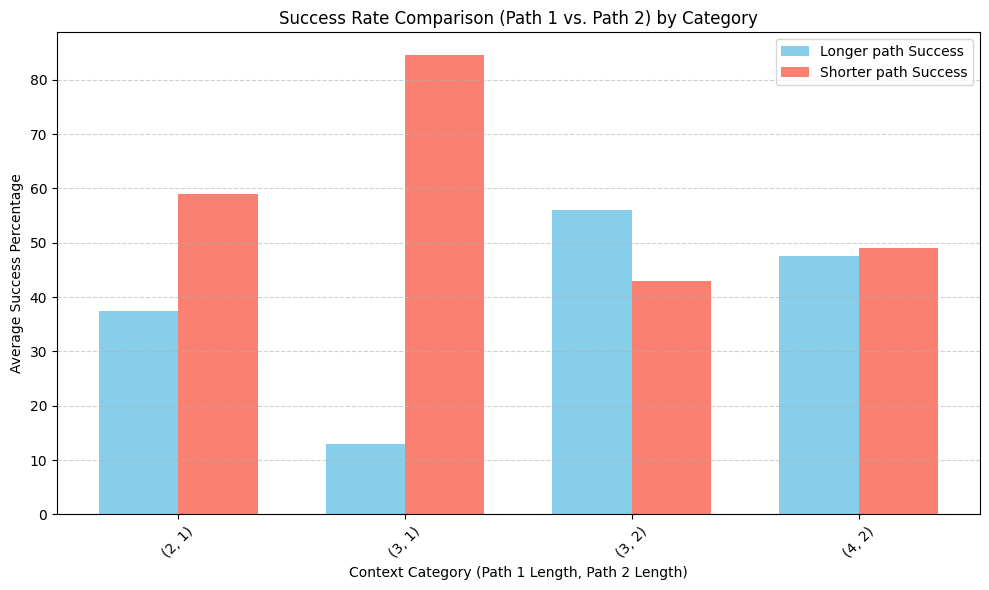

In [322]:
plot_grouped_bar_chart(df_agg)

## Rest:

In [85]:
num_retries = 100
all_prompts = []
# all_prompts.extend([prompt] * num_retries)
for i in range(num_retries):
    random.shuffle(sample['Context'])
    prompt = f"""Question: {sample['Question']}\n\n
        
        Context:\n
        {sample['Context']}\n\n        
        """
    all_prompts.append(prompt)

In [90]:
num_retries = 100
all_prompts = []
# all_prompts.extend([prompt] * num_retries)
for i in range(num_retries):
    random.shuffle(sample['Context'])
    prompt = f"""Question: {"Which is the largest pharmaceutical manufacturer in the United States?"}\n\n
        
        Context:\n
        {sample['Context']}\n\n        
        """
    all_prompts.append(prompt)

In [91]:
nested_answers = await qa_context_model.async_run(all_prompts)

Usage cost: 0.0232$ (Estimated: 0.02$): 100%|████████████████████████████████████████| 100/100 [00:04<00:00, 22.27it/s]


In [92]:
nested_answers

['Rivermore Biomedica',
 'Rivermore Biomedica',
 'Northstar Therapeutics',
 'Rivermore Biomedica',
 'Rivermore Biomedica',
 'Northstar Therapeutics',
 'Rivermore Biomedica',
 'Rivermore Biomedica',
 'Northstar Therapeutics',
 'Rivermore Biomedica',
 'Northstar Therapeutics',
 'Rivermore Biomedica',
 'Northstar Therapeutics',
 'Rivermore Biomedica',
 'Rivermore Biomedica',
 'Northstar Therapeutics',
 'Rivermore Biomedica',
 'Rivermore Biomedica',
 'Rivermore Biomedica',
 'Rivermore Biomedica',
 'Rivermore Biomedica',
 'Northstar Therapeutics',
 'Rivermore Biomedica',
 'Northstar Therapeutics',
 'Northstar Therapeutics',
 'Rivermore Biomedica',
 'Northstar Therapeutics',
 'Rivermore Biomedica',
 'Northstar Therapeutics',
 'Northstar Therapeutics',
 'Rivermore Biomedica',
 'Northstar Therapeutics',
 'Northstar Therapeutics',
 'Northstar Therapeutics',
 'Rivermore Biomedica',
 'Rivermore Biomedica',
 'Rivermore Biomedica',
 'Rivermore Biomedica',
 'Rivermore Biomedica',
 'Northstar Therape

In [77]:
from collections import defaultdict

def string_frequency_dict(string_list):
    """
    Converts a list of strings into a dictionary where each string is a key
    and its value is the frequency of that string in the list.

    Args:
        string_list: A list of strings.

    Returns:
        A dictionary with string keys and integer frequency values.
    """
    frequency_dict = defaultdict(int)
    for s in string_list:
        frequency_dict[s] += 1
    return dict(frequency_dict)

In [93]:
string_frequency_dict(nested_answers)

{'Rivermore Biomedica': 49, 'Northstar Therapeutics': 50, 'No answer': 1}

In [88]:
string_frequency_dict(nested_answers)

{'Evan Holt': 94, 'Marissa Holt': 1, 'No answer': 2, 'Dr. Lila Kessler': 3}